<a href="https://colab.research.google.com/github/vishwa24816/Value-at-risk-and-expected-shortfall-/blob/main/Value_at_risk_and_expected_shortfall.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# !pip install yfinance pandas numpy scipy matplotlib  # uncomment if needed
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
TICKER = "AAPL"          # change to any stock symbol
START = "2006-01-01"
END = "2026-01-01"

data = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
prices = data["Close"].squeeze()
print(f"Downloaded {len(prices)} trading days for {TICKER}")
prices.tail()

Downloaded 5031 trading days for AAPL


,AAPL
Date,
2025-12-24,273.066711
2025-12-26,272.657867
2025-12-29,273.016876
2025-12-30,272.338684
2025-12-31,271.122009


In [3]:
returns = np.log(prices / prices.shift(1)).dropna()
print(f"Mean daily return: {returns.mean():.4%}")
print(f"Daily volatility:  {returns.std():.4%}")
returns.describe()

Mean daily return: 0.0954%
Daily volatility:  2.0016%


,AAPL
count,5030.000000
mean,0.000954
std,0.020016
min,-0.197470
25%,-0.008184
50%,0.000986
75%,0.011225
max,0.142617


In [6]:
def var_es(returns, confidence=0.95):
    """Return (VaR, ES) as positive loss numbers, using historical simulation."""
    var = -np.percentile(returns, (1 - confidence) * 100)
    tail = returns[returns <= -var]
    es = -tail.mean()
    return var, es

results = {}
for c in [0.98]:
    var, es = var_es(returns, c)
    results[f"{int(c*100)}%"] = {"VaR (1-day)": var, "ES (1-day)": es}

summary = pd.DataFrame(results).T
summary = summary.map(lambda x: f"{x:.2%}")
summary

,VaR (1-day),ES (1-day)
98%,4.33%,6.21%


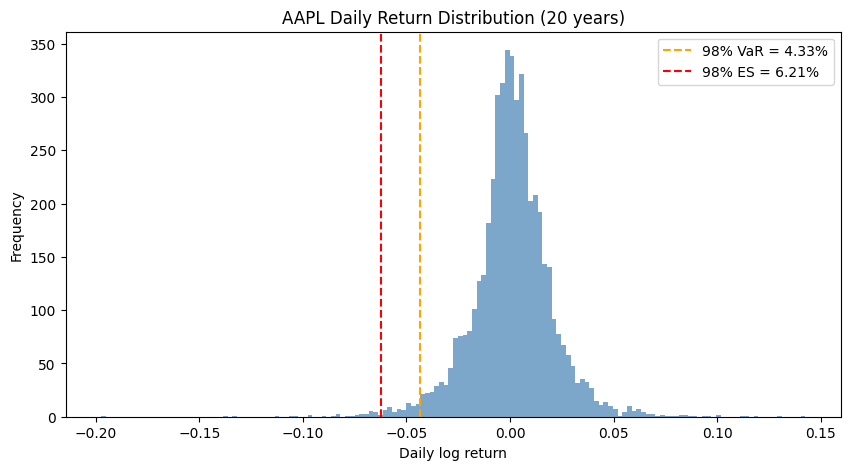

In [8]:
var95, es95 = var_es(returns, 0.98)

plt.figure(figsize=(10, 5))
plt.hist(returns, bins=150, color="steelblue", alpha=0.7)
plt.axvline(-var95, color="orange", linestyle="--", label=f"98% VaR = {var95:.2%}")
plt.axvline(-es95, color="red", linestyle="--", label=f"98% ES = {es95:.2%}")
plt.title(f"{TICKER} Daily Return Distribution (20 years)")
plt.xlabel("Daily log return")
plt.ylabel("Frequency")
plt.legend()
plt.show()